In [37]:
# Multilayer Perceptron for Character Recognition using MNIST

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.datasets import mnist

In [38]:
# 1. Load the MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

In [39]:
# 2. Normalize pixel values
x_train = x_train / 255.0
x_test = x_test / 255.0

In [40]:
# 3. Create the MLP model
model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [41]:
# 4. Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [42]:
# 5. Train the model
model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9258 - loss: 0.2570 - val_accuracy: 0.9680 - val_loss: 0.1065
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9679 - loss: 0.1070 - val_accuracy: 0.9742 - val_loss: 0.0869
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9760 - loss: 0.0750 - val_accuracy: 0.9745 - val_loss: 0.0836
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9825 - loss: 0.0555 - val_accuracy: 0.9732 - val_loss: 0.0905
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9856 - loss: 0.0441 - val_accuracy: 0.9770 - val_loss: 0.0842


In [43]:
# 6. Evaluate the model
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9756 - loss: 0.0842
Test Accuracy: 0.975600004196167


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step


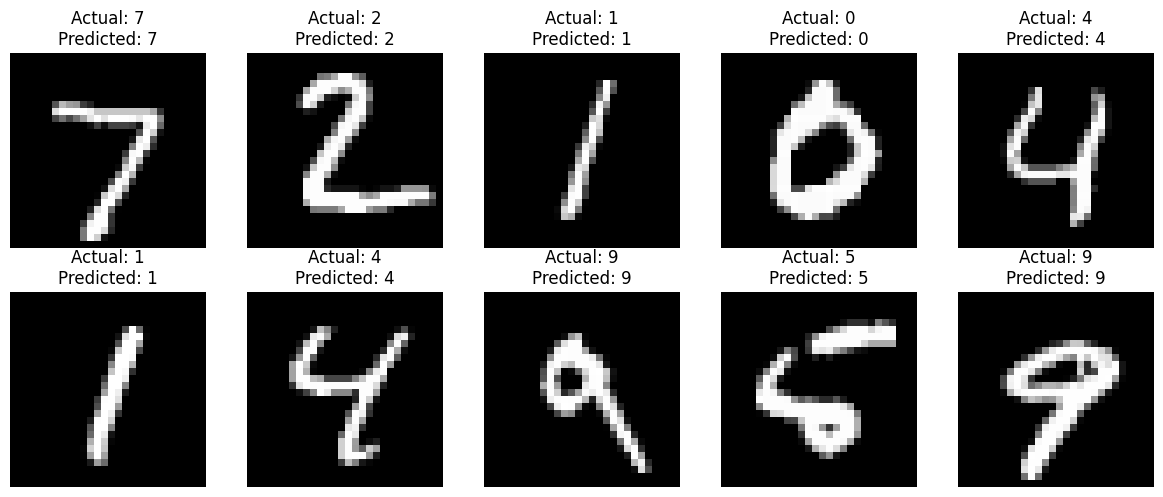

In [44]:
# 7. Predict and display handwritten images

import matplotlib.pyplot as plt
import numpy as np

predictions = model.predict(x_test[:10])

plt.figure(figsize=(12, 5))

for i in range(10):
    predicted_digit = np.argmax(predictions[i])

    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    plt.title(
        f"Actual: {y_test[i]}\nPredicted: {predicted_digit}"
    )
    plt.axis('off')

plt.tight_layout()
plt.show()